# Calculus with Sagebrush

Symbolic expressions, derivatives, limits, integrals, series and differential equations, computed in this page by Sagebrush's own symbolic engine (Rust, compiled to WebAssembly) and printed the way Sage prints them. Every antiderivative is checked by differentiating it. Drag the sliders below: each change reruns the cell.

In [ ]:
f = x^3 - 3*x
f, diff(f, x), solve(diff(f, x) == 0, x)

(x^3 - 3*x, 3*x^2 - 3, [x == -1, x == 1])


In [ ]:
limit(sin(x)/x, x=0), limit((1 + 1/x)^x, x=oo), limit(x^10*exp(-x), x=oo)

(1, e, 0)


In [ ]:
integrate(x^2*exp(x), x)

(x^2 - 2*x + 2)*e^x


`integrate_steps` shows how an antiderivative was found, rule by rule; `show` typesets.

In [ ]:
show(integrate_steps(x*cos(x^2), x))

integral of x*cos(x^2) dx = 1/2*sin(x^2)   [substitute u = x^2]
  integral of 1/2*cos(u) du = 1/2*sin(u)   [constant multiple]
    integral of cos(u) du = sin(u)   [table]

In [ ]:
integrate(1/(1 + x^2), x, 0, oo), integrate(exp(-x^2), x, -oo, oo), numerical_integral(sin(x)/x, 0, pi)

(1/2*pi, sqrt(pi), (1.851937051982466, 1.1509966043428485e-14))


## Tangent lines, Taylor polynomials, Riemann sums

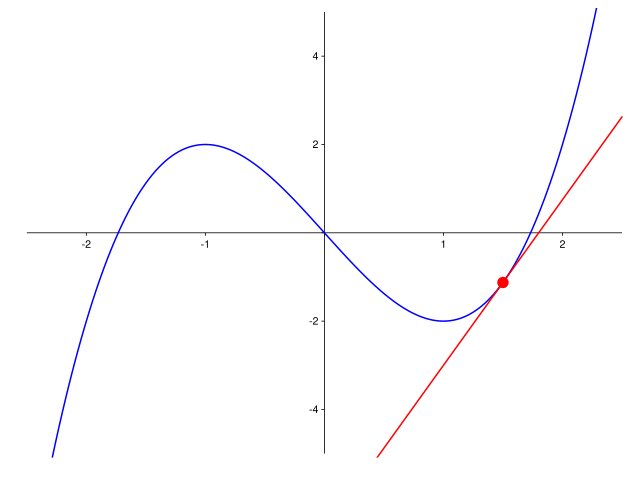

In [ ]:
@interact
def tangent(a=slider(-2, 2, 0.1, 1.5)):
    f = x^3 - 3*x
    m = diff(f, x)(x=a)
    t = f(x=a) + m*(x - a)
    show(plot(f, (x, -2.5, 2.5)) + plot(t, (x, -2.5, 2.5), color='red') + point((a, f(x=a)), size=40, color='red'), ymin=-5, ymax=5)

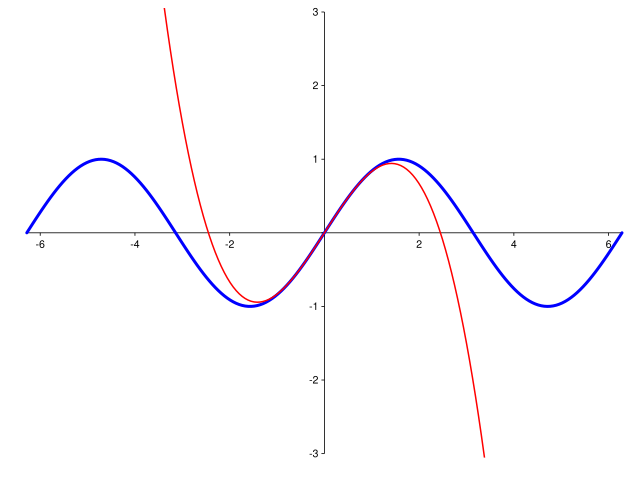

-1/6*x^3 + x

In [ ]:
@interact
def taylor_polynomials(n=slider(1, 15, 1, 3)):
    p = taylor(sin(x), x, 0, n)
    show(plot(sin(x), (x, -2*pi, 2*pi), thickness=2) + plot(p, (x, -2*pi, 2*pi), color='red'), ymin=-3, ymax=3)
    show(p)

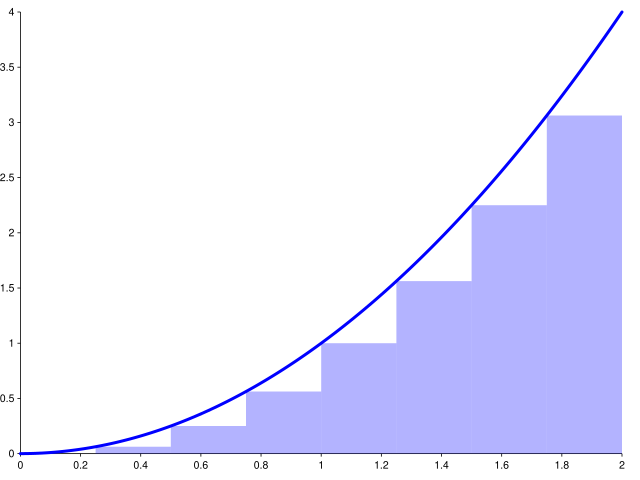

left Riemann sum: 2.18750000000000    integral: 8/3


In [ ]:
@interact
def riemann_sum(n=slider(2, 40, 1, 8)):
    f = x^2
    a, b = 0, 2
    h = (b - a)/n
    rects = sum(polygon([(a + i*h, 0), (a + (i+1)*h, 0), (a + (i+1)*h, f(x=a + i*h)), (a + i*h, f(x=a + i*h))], alpha=0.3) for i in range(n))
    show(plot(f, (x, a, b), thickness=2) + rects)
    print('left Riemann sum:', sum(f(x=a + i*h)*h for i in range(n)).n(), '   integral:', integrate(f, x, a, b))

## Functions of two variables

Drag the surface to turn it; scroll (after a click) to zoom.

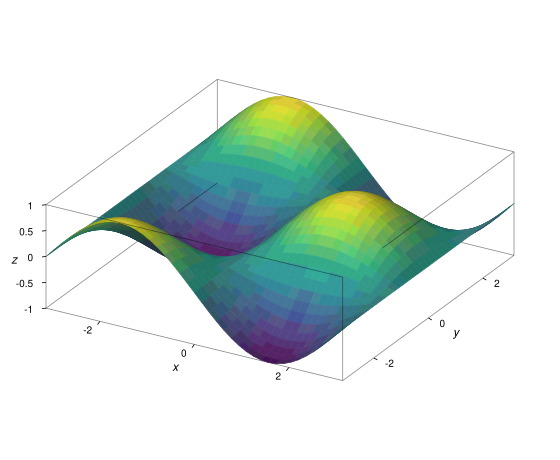

In [ ]:
y = var('y')
plot3d(sin(x)*cos(y), (x, -pi, pi), (y, -pi, pi), cmap='viridis')

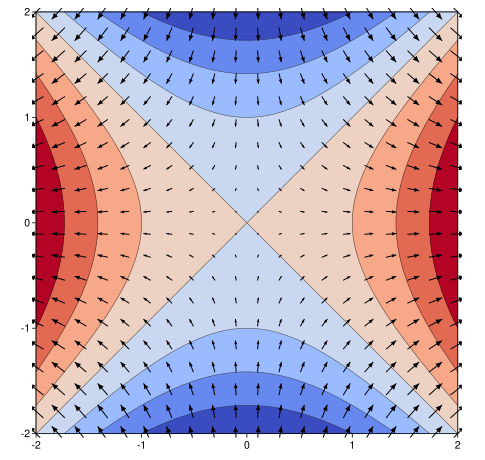

In [ ]:
contour_plot(x^2 - y^2, (x, -2, 2), (y, -2, 2), cmap='coolwarm') + plot_vector_field((2*x, -2*y), (x, -2, 2), (y, -2, 2), color='black')

## Differential equations

In [ ]:
y = function('y')(x)
desolve(diff(y, x, 2) + 4*y == sin(x), y)

_K2*cos(2*x) + _K1*sin(2*x) + 1/3*sin(x)


x + 2*e^(-x) - 1

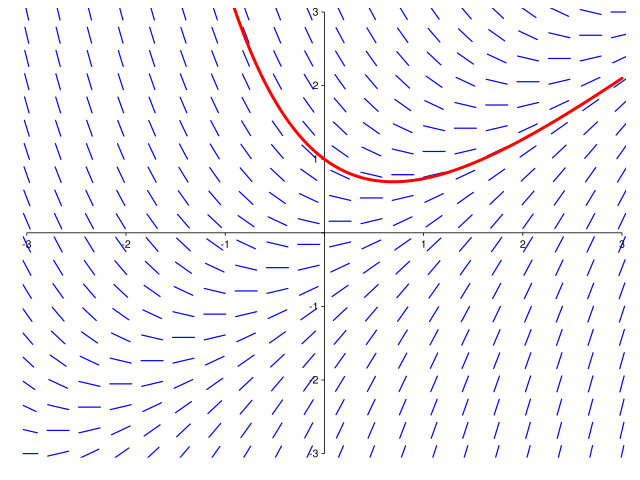

In [ ]:
sol = desolve(diff(y, x) == x - y, y, ics=[0, 1])
u = var('u')
show(sol)
plot_slope_field(x - u, (x, -3, 3), (u, -3, 3)) + plot(sol, (x, -3, 3), color='red', thickness=2, ymin=-3, ymax=3)

## Series

In [ ]:
taylor(exp(x)*sin(x), x, 0, 6), sin(x).series(x, 8)

(-1/90*x^6 - 1/30*x^5 + 1/3*x^3 + x^2 + x, 1*x + (-1/6)*x^3 + 1/120*x^5 + (-1/5040)*x^7 + Order(x^8))
